# 00 · simple RAG (the baseline)

I'm learning how Corrective RAG (CRAG) works by implementing it step by step, with the paper as my reference:
Yan et al., 2024, [Corrective Retrieval Augmented Generation](https://arxiv.org/abs/2401.15884).

Plan for the notebooks:
- 00 simple RAG, the baseline I'm going to fix
- 01 retrieval evaluator + knowledge refinement (the CORRECT path)
- 02 query rewrite + web search (the INCORRECT path)
- 03 using book and web knowledge together (the AMBIGUOUS path)
- 04 everything together + simple RAG vs CRAG

## why start with plain RAG

Before fixing anything I want to actually see the problem. The paper's whole point is that normal RAG trusts whatever the retriever gives it. A vector store always returns the top k closest chunks, even when none of them are about the question. Then the LLM either:

1. says "I don't know" (best case)
2. answers from its own memory (parametric knowledge). looks fine, but it's not from my data
3. makes something up from the irrelevant chunks (worst case)

So here I build a basic RAG over 3 ML textbooks and then try to break it.

## setup

In [2]:
import logging
import os
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)  # langchain-community sunset notice
from pathlib import Path
from typing import TypedDict

from dotenv import load_dotenv
from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langgraph.graph import StateGraph, START, END

logging.getLogger("pypdf").setLevel(logging.ERROR)  # PDF font-parsing noise

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
load_dotenv(PROJECT_ROOT / ".env")

DATA_DIR = PROJECT_ROOT / "data"
INDEX_DIR = PROJECT_ROOT / "vectorstore" / "faiss_index"

CHAT_MODEL = os.environ["OPENAI_CHAT_MODEL"]
EMBEDDING_MODEL = os.environ["OPENAI_EMBEDDING_MODEL"]
print(f"chat model: {CHAT_MODEL} | embedding model: {EMBEDDING_MODEL}")

chat model: gpt-4o-mini | embedding model: text-embedding-3-small


## step 1: load the pdfs

Every pdf in `data/` gets loaded page by page. Each page becomes a `Document` with `source` and `page` in the metadata, which is handy later for showing where a chunk came from.

In [3]:
pdf_paths = sorted(DATA_DIR.glob("*.pdf"))
assert pdf_paths, f"No PDFs found in {DATA_DIR}. Download the books listed in the README first."

docs: list[Document] = []
for path in pdf_paths:
    pages = PyPDFLoader(str(path)).load()
    docs.extend(pages)
    print(f"{path.name:<55} {len(pages):>5} pages")

print(f"\nTotal pages loaded: {len(docs)}")

Bishop-Pattern-Recognition-and-Machine-Learning-2006.pdf   758 pages
ISLP_website.pdf                                          613 pages
mml-book.pdf                                              417 pages

Total pages loaded: 1788


## step 2: chunking

chunk_size 900, overlap 150. Nothing fancy.

One thing to keep in mind: the splitter just cuts by characters, it doesn't care about topics. So one chunk can end up with half of one idea and half of another. This comes back in 01 (knowledge refinement).

Also the pdf text had some broken unicode characters that crashed the embedding call, so I clean those out first.

In [4]:
def clean_text(text: str) -> str:
    return text.encode("utf-8", "ignore").decode("utf-8", "ignore")

for d in docs:
    d.page_content = clean_text(d.page_content)

splitter = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=150)
chunks = splitter.split_documents(docs)
chunks = [c for c in chunks if c.page_content.strip()]

print(f"{len(docs)} pages -> {len(chunks)} chunks")
print("\nSample chunk:\n" + "-" * 60)
print(chunks[len(chunks) // 2].page_content)

1788 pages -> 5933 chunks

Sample chunk:
------------------------------------------------------------
Consider again the Default data set, where the response default falls into
one of two categories, Yes or No. Rather than modeling this response Y
directly, logistic regression models the probability that Y belongs to a par-
ticular category.
For the Defaultdata, logistic regression models the probability of default.
For example, the probability of default given balance can be written as
Pr(default = Yes|balance).
The values of Pr(default = Yes|balance), which we abbreviate p(balance),
will range between 0 and 1. Then for any given value of balance, a prediction
can be made for default. For example, one might predict default = Yes


## step 3: embeddings + FAISS

Embedding everything once and saving the index to disk, so the other notebooks just load it instead of paying again.

`allow_dangerous_deserialization=True` is there because FAISS saves the metadata with pickle. Fine for an index I built myself, I wouldn't load someone else's like this.

In [5]:
embeddings = OpenAIEmbeddings(model=EMBEDDING_MODEL)

if INDEX_DIR.exists():
    vectorstore = FAISS.load_local(str(INDEX_DIR), embeddings, allow_dangerous_deserialization=True)
    print(f"Loaded existing index from {INDEX_DIR}")
else:
    vectorstore = FAISS.from_documents(chunks, embeddings)
    vectorstore.save_local(str(INDEX_DIR))
    print(f"Built and saved new index to {INDEX_DIR}")

print(f"Vectors in index: {vectorstore.index.ntotal}")

retriever = vectorstore.as_retriever(search_type="similarity", search_kwargs={"k": 4})

Loaded existing index from /Users/shishirrijal/Desktop/Projects/Corrective-RAG/vectorstore/faiss_index
Vectors in index: 5933


## step 4: the graph

Simplest possible graph, two nodes:

```
START → retrieve → generate → END
```

The state is just a dict that every node reads from and writes to. In the next notebooks I'll mostly be adding fields
to this state and adding nodes, the basic structure stays.

In [6]:
llm = ChatOpenAI(model=CHAT_MODEL, temperature=0)


class State(TypedDict):
    question: str
    docs: list[Document]
    answer: str


def retrieve_node(state: State) -> dict:
    return {"docs": retriever.invoke(state["question"])}


answer_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are a helpful ML tutor. Answer ONLY using the provided context. "
     "If the context is empty or insufficient, say: 'I don't know.'"),
    ("human", "Question: {question}\n\nContext:\n{context}"),
])


def generate_node(state: State) -> dict:
    context = "\n\n".join(d.page_content for d in state["docs"])
    out = (answer_prompt | llm).invoke({"question": state["question"], "context": context})
    return {"answer": out.content}


g = StateGraph(State)
g.add_node("retrieve", retrieve_node)
g.add_node("generate", generate_node)
g.add_edge(START, "retrieve")
g.add_edge("retrieve", "generate")
g.add_edge("generate", END)
app = g.compile()

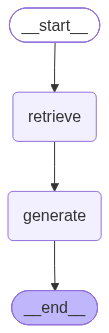

In [7]:
from IPython.display import Image, display

try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception:  # rendering needs internet (mermaid.ink); fall back to text
    print(app.get_graph().draw_mermaid())

## step 5: testing it

Same 4 questions in every notebook, so I can compare how things change as I add stuff.

- `in_corpus`: bias-variance trade-off. it's in the books, should work fine
- `recent`: AI news from last month. no way that's in textbooks
- `out_of_corpus`: transformer architecture. not in my books, but the LLM obviously knows it, so this one is for spotting answers coming from memory
- `partial`: SVM vs XGBoost. SVMs are in the books, XGBoost isn't. half covered

In [8]:
TEST_QUERIES = {
    "in_corpus": "Explain the bias-variance trade-off.",
    "recent": "What were the top AI news stories in the last month?",
    "out_of_corpus": "What is the transformer architecture in deep learning?",
    "partial": "Compare support vector machines with XGBoost for tabular data.",
}


def run(key: str) -> dict:
    result = app.invoke({"question": TEST_QUERIES[key]})
    print(f"Q: {result['question']}\n")
    print("Retrieved chunks:")
    for i, d in enumerate(result["docs"], 1):
        src = Path(d.metadata.get("source", "?")).name
        snippet = " ".join(d.page_content.split())[:220]
        print(f"  [{i}] {src} p.{d.metadata.get('page', '?')}: {snippet}...")
    print(f"\nAnswer:\n{result['answer']}")
    return result

### in-corpus question

In [9]:
r_in = run("in_corpus")

Q: Explain the bias-variance trade-off.

Retrieved chunks:
  [1] ISLP_website.pdf p.47: The bias-variance tradeoff, and the resulting U-shape in the test error, can make this a difficult task. In Chapter 5, we return to this topic and discuss...
  [2] ISLP_website.pdf p.43: high variance (for instance, by drawing a curve that passes through every single training observation) or a method with very low variance but high bias (by fitting a horizontal line to the data). The challenge lies in fi...
  [3] ISLP_website.pdf p.43: ure 2.12, as flexibility increases, there is a dramatic decline in bias because the true f is very non-linear. There is also very little increase in variance as flexibility increases. Consequently, the test MSE declines ...
  [4] Bishop-Pattern-Recognition-and-Machine-Learning-2006.pdf p.166: to consider a frequentist viewpoint of the model complexity issue, known as thebias- variance trade-off. Although we shall introduce this concept in the context of linear basis f

All 4 chunks are actually about bias and variance. When retrieval is good, plain RAG is good. No complaints here.

### recent news

In [10]:
r_recent = run("recent")

Q: What were the top AI news stories in the last month?

Retrieved chunks:
  [1] ISLP_website.pdf p.405: ematicians and statisticians; algorithms were improved, and the method- ology stabilized. Then along came SVMs, boosting, and random forests, and neural networks fell somewhat from favor. Part of the reason was that neur...
  [2] ISLP_website.pdf p.405: 10 Deep Learning This chapter covers the important topic of deep learning . At the time of deep learningwriting (2020), deep learning is a very active area of research in the machine learning and artificial intelligence ...
  [3] ISLP_website.pdf p.431: Algorithms used to fit RNNs can be complex and computationally costly. Fortunately, good software protects users somewhat from these complexi- ties, and makes specifying and fitting these models relatively painless. Many...
  [4] ISLP_website.pdf p.405: of success stories on some niche problems such as image and video classifi- cation, speech and text modeling. Many in the field belie

The 4 chunks are just the closest vectors, and closest doesn't mean relevant. Best case the model says "I don't know",
but then the user still gets nothing.

### transformer (not in the books)

In [11]:
r_ooc = run("out_of_corpus")

Q: What is the transformer architecture in deep learning?

Retrieved chunks:
  [1] ISLP_website.pdf p.416:   → [3524 ] . 10.3.3 Architecture of a Convolutional Neural Network So far we have defined a single convolution layer — each filter produces a new two-dimensional feature map. The number of convolution filters in a c...
  [2] ISLP_website.pdf p.457: 10.9 Lab: Deep Learning 451 ReLU: 2-7 [128, 512] [128, 512] -- Linear: 2-8 [128, 512] [128, 100] 51,300 ====================================================================== Total params: 964,516 Trainable params: 964,5...
  [3] ISLP_website.pdf p.418: 412 10. Deep Learning FIGURE 10.9. Data augmentation. The original image (leftmost) is distorted in natural ways to produce different images with the same class label. These distortions do not fool humans, and act as a f...
  [4] ISLP_website.pdf p.454: 448 10. Deep Learning mnist_model, mnist_dm, mnist_trainer, mnist_module, mnist_results, mlr_model, mlr_module, mlr_trainer) 10.9.3

This one is interesting. Look at the retrieved chunks, none of them are about transformers, it's CNN stuff.

With my strict prompt ("answer ONLY from context") the model says I don't know. Safe, but useless. A lot of RAG apps
use a looser prompt though, so let me send the exact same chunks with one:

In [11]:
naive_prompt = ChatPromptTemplate.from_messages([
    ("system", "You are a helpful ML tutor. Use the following context to answer the question."),
    ("human", "Question: {question}\n\nContext:\n{context}"),
])


def answer_with_naive_prompt(result: dict) -> str:
    context = "\n\n".join(d.page_content for d in result["docs"])
    return (naive_prompt | llm).invoke({"question": result["question"], "context": context}).content


print(answer_with_naive_prompt(r_ooc))

The transformer architecture in deep learning is a model designed primarily for processing sequential data, such as natural language. Introduced in the paper "Attention is All You Need" by Vaswani et al. in 2017, the transformer architecture is notable for its use of self-attention mechanisms, which allow the model to weigh the importance of different words in a sentence regardless of their position.

Key components of the transformer architecture include:

1. **Self-Attention Mechanism**: This allows the model to consider the relationships between all words in a sequence simultaneously, enabling it to capture context more effectively than previous architectures like RNNs or LSTMs, which processed data sequentially.

2. **Multi-Head Attention**: The transformer uses multiple attention heads to capture different aspects of the relationships between words. Each head learns to focus on different parts of the input sequence.

3. **Positional Encoding**: Since transformers do not inherently

Same chunks, and now there's a confident, detailed answer. None of that came from my documents. It's the model's own
memory leaking through.

Here it's harmless because the model happens to know transformers. But if the question was about something like a
company's leave policy, the same behavior is a hallucination someone might act on.

So plain RAG is kind of stuck:
- strict prompt: "I don't know". safe but useless
- loose prompt: answers anyway from memory. not grounded

And the real problem is earlier in the pipeline. Nothing checks whether retrieval actually worked.

### SVM vs XGBoost (half covered)

In [13]:
r_partial = run("partial")

Q: Compare support vector machines with XGBoost for tabular data.

Retrieved chunks:
  [1] ISLP_website.pdf p.394: 388 9. Support Vector Machines In [6]:fig, ax = subplots(figsize=(8,8)) plot_svm(X, y, svm_linear, ax=ax) The decision boundary between the two classes is linear (because we used the argumentkernel='linear'). The support...
  [2] ISLP_website.pdf p.368: 362 8. Tree-Based Methods ax.plot(plot_idx, test_error, 'r', label= 'Test' ) ax.legend(); We now use the boosted model to predict medv on the test set: In [31]: y_hat_boost = boost_boston.predict(X_test); np.mean((y_test...
  [3] ISLP_website.pdf p.399: 9.6 Lab: Support Vector Machines 393 C=1) svm_flex.fit(X_train, y_train) fig, ax = subplots(figsize=(8,8)) roc_curve(svm_flex, X_train, y_train, name= 'Training $\gamma=50$' , color= 'r', ax=ax); However, these ROC curve...
  [4] ISLP_website.pdf p.400: 394 9. Support Vector Machines We now fit an SVM to the data: In [31]:svm_rbf_3 = SVC(kernel="rbf", C=10, gamma=1, decision

Look at the strict prompt answer above again. It talks about specific XGBoost stuff (hyperparameters, speed, being
popular in competitions). Did that come from the books? Checking:

In [14]:
corpus = vectorstore.docstore._dict.values()  # every chunk stored in FAISS
print("chunks mentioning 'xgboost':", sum("xgboost" in d.page_content.lower() for d in corpus))

chunks mentioning 'xgboost': 0


Zero chunks mention XGBoost. So every XGBoost detail came from the model's memory, even with the strict
"only from context" prompt.

My guess at what's happening: when part of the context is relevant (SVMs, boosting in general), the model takes that as
permission to fill in the rest from memory. The strict prompt only really works when the context is obviously useless.

Loose prompt does the same, just more openly:

In [15]:
print(answer_with_naive_prompt(r_partial))

Support Vector Machines (SVM) and XGBoost are both powerful machine learning algorithms commonly used for tabular data, but they have different characteristics, strengths, and weaknesses.

### Support Vector Machines (SVM)

1. **Mechanism**: SVM works by finding the hyperplane that best separates different classes in the feature space. It focuses on maximizing the margin between the closest points of the classes, known as support vectors.

2. **Kernel Trick**: SVM can use different kernel functions (like linear, polynomial, or radial basis function) to handle non-linear relationships in the data. This flexibility allows SVM to model complex decision boundaries.

3. **Hyperparameters**: Key hyperparameters include the cost parameter (C), which controls the trade-off between maximizing the margin and minimizing classification error, and the kernel parameters (like gamma for RBF kernels).

4. **Interpretability**: For linear SVMs, the coefficients of the decision boundary can be interpret

Plain RAG has no way to say "this is half covered, use the good part and go find the rest". And you can't even see
the leak, there's no way to tell which sentences came from the books and which didn't.